<a href="https://colab.research.google.com/github/jkirkpa6-az/Capstone_Project/blob/main/CatBoost_for_cannabis_use_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DAT 490 Methodology Part 1
## Autumn Towne

### **Step 0: Importing libraries and dataset**

In [6]:
%%capture

!pip install catboost

In [7]:
%%capture

!pip install ipywidgets

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import scipy.stats as stats
import warnings
from catboost import CatBoostClassifier, Pool
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, f1_score

In [9]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [10]:
nsduh_2021_2024 = pd.read_csv('/content/drive/MyDrive/nsduh_2021_2024.csv')

/tmp/ipykernel_1730/2466007834.py:1: DtypeWarning: Columns (2281) have mixed types. Specify dtype option on import or set low_memory=False.
  nsduh_2021_2024 = pd.read_csv('/content/drive/MyDrive/nsduh_2021_2024.csv')


### **Step 1: Initial variable selection**
The response variable I investigate is MRJFLAG: if the respondent ever used marijuana.
The predictor variables I chose are "GRSKMRJMON", "GRSKMRJWK", and "DIFGETMRJ".

The first two variables are related to risk. Respondents were asked "How much do people risk harming themselves physically and in other ways when they smoke marijuana once a month?", and could select "No risk", "Slight risk", "Moderate risk", or "Great Risk".

GRSKMRJMON is that question recoded as binary with 1 being the respondent selected "Great Risk". GRSKMRJWK is the same except the question was "once or twice a week" rather than "once a month".

DIFGETMRJ was the question "How difficult or easy would it be for you to get some marijuana, if you wanted some?" Options were "Probably impossible", "Very difficult", "Fairly difficult", "Fairly easy", or "Very Easy".

In [11]:
X = nsduh_2021_2024[["GRSKMRJMON", "GRSKMRJWK", "DIFGETMRJ"]].astype(str)
y = nsduh_2021_2024["MRJFLAG"]

### **Step 2: Train/test split, model selection, and hyperparameter adjustments**

I used the default train and test size split: 75% training and 25% testing. I used 500 iterations because that is a typical maximum number of trees for a model like this. CatBoostClassifier's default learning rate is selected automatically for binary classification, so I did not change it. I left the depth at its default of 6.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y)

model = CatBoostClassifier(iterations = 500, silent = True)

model.fit(X_train, y_train,
          cat_features=["GRSKMRJMON", "GRSKMRJWK", "DIFGETMRJ"])

CatBoostClassifier(iterations=500, silent=True)

### **Step 3: Model evaluation**
I calculated the accuracy and F1 score of the model and displayed a confusion matrix. I will later calculate feature importance.

In [13]:
print("Test accuracy:", model.score(X_test, y_test))

y_pred = model.predict(X_test)

f1 = f1_score(y_test, y_pred)
print(f"Binary F1 Score: {f1:.4f}")

Test accuracy: 0.7307566553664538
Binary F1 Score: 0.7273


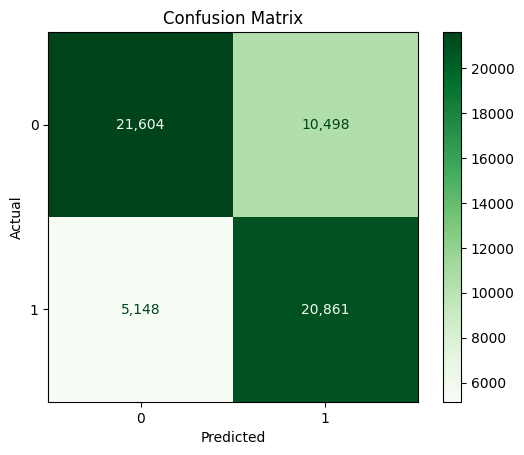

In [14]:
# Get predictions from the trained model
y_pred = model.predict(X_test)

# Compute the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
disp.plot(cmap=plt.cm.Greens, values_format=',d')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

## **Step 4: Adding variables and repeating Steps 1-3**

This time, I let the iterations be set to the default number (1000).

I added the variable "COUTYP4": the metro status of the respondent's county, with 1 for Large Metro, 2 for Small Metro, and 3 for Nonmetro.


In [15]:
X = nsduh_2021_2024[
    ["GRSKMRJMON", "GRSKMRJWK", "DIFGETMRJ", "COUTYP4"]].astype(str)
y = nsduh_2021_2024["MRJFLAG"]

X_train, X_test, y_train, y_test = train_test_split(X, y)

model = CatBoostClassifier(silent = True)

model.fit(X_train, y_train,
          cat_features=["GRSKMRJMON", "GRSKMRJWK", "DIFGETMRJ", "COUTYP4"])

CatBoostClassifier(silent=True)

Test accuracy: 0.7274182168608353
Binary F1 Score: 0.7239


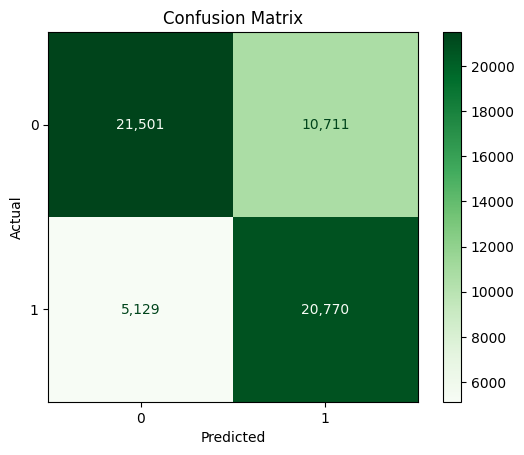

In [16]:
print("Test accuracy:", model.score(X_test, y_test))

y_pred = model.predict(X_test)

f1 = f1_score(y_test, y_pred)
print(f"Binary F1 Score: {f1:.4f}")

# Get predictions from the trained model
y_pred = model.predict(X_test)

# Compute the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
disp.plot(cmap=plt.cm.Greens, values_format=',d')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

**Metro status did not significantly improve the model.**

I then added the following variables related to availability, attitude, and religion:

* APPDRGMON2 is if someone has approached them trying to sell drugs in the past month.

* SNFAMJEV is "How do you feel about adults trying marijuana or any cannabis product once or twice?"

* SNRLGSVC is "During the past 12 months, how many times did you attend religious services excluding special occasions such as weddings or funerals?"

* SNYSELL is "During the past 12 months, how many times have you sold illegal drugs?"

* SNRLGIMP: Are your religious beliefs a very important part of your life?

* SNRLDCSN Do your religious beliefs influence how you make decisions in your life?

The dataset had multiple different error codes, so I collapsed all error codes into NaNs, leaving the true variable values as-is.

In [17]:
nsduh_2021_2024['SNFAMJEV'] = nsduh_2021_2024['SNFAMJEV'].where(
    nsduh_2021_2024['SNFAMJEV'].isin([1, 2, 3]), np.nan)

nsduh_2021_2024['SNRLGSVC'] = nsduh_2021_2024['SNRLGSVC'].where(
    nsduh_2021_2024['SNRLGSVC'].isin([1, 2, 3, 4, 5, 6]), np.nan)

nsduh_2021_2024['SNYSELL'] = nsduh_2021_2024['SNYSELL'].where(
    nsduh_2021_2024['SNYSELL'].isin([1, 2, 3, 4, 5]), np.nan)

nsduh_2021_2024['SNRLGIMP'] = nsduh_2021_2024['SNRLGIMP'].where(
    nsduh_2021_2024['SNRLGIMP'].isin([1, 2, 3, 4]), np.nan)

nsduh_2021_2024['SNRLDCSN'] = nsduh_2021_2024['SNRLDCSN'].where(
    nsduh_2021_2024['SNRLDCSN'].isin([1, 2, 3, 4]), np.nan)

In [18]:
X = nsduh_2021_2024[
    ["GRSKMRJMON", "GRSKMRJWK", "DIFGETMRJ", "COUTYP4", "APPDRGMON2",
     "SNFAMJEV", "SNRLGSVC", "SNYSELL", "SNRLGIMP", "SNRLDCSN"]].astype(str)
y = nsduh_2021_2024["MRJFLAG"]

X_train, X_test, y_train, y_test = train_test_split(X, y)

model = CatBoostClassifier(silent = True)

model.fit(X_train, y_train,
          cat_features=["GRSKMRJMON", "GRSKMRJWK", "DIFGETMRJ", "COUTYP4",
                        "APPDRGMON2", "SNFAMJEV", "SNRLGSVC", "SNYSELL",
                        "SNRLGIMP", "SNRLDCSN"])

CatBoostClassifier(silent=True)

Test accuracy: 0.7604584329989159
Binary F1 Score: 0.7418


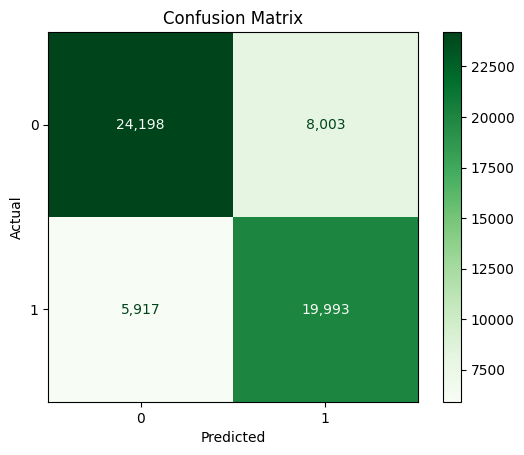

In [19]:
print("Test accuracy:", model.score(X_test, y_test))

y_pred = model.predict(X_test)

f1 = f1_score(y_test, y_pred)
print(f"Binary F1 Score: {f1:.4f}")

# Get predictions from the trained model
y_pred = model.predict(X_test)

# Compute the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
disp.plot(cmap=plt.cm.Greens, values_format=',d')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

**Availability, attitude, and religion variables improved the model.**

Lastly, I added mental health variables:

* IRAMDELT lifetime major depressive episode.

* IRAMDEIMP major depressive episode with severe role impairment.

* SMIPY Serious Mental Illness (SMI) indicator for respondents based on the 2012 predicted probability of SMI if it is greater than or equal to a specified cutoff point (0.260573529) then SMIPY=1, and if SMIPPPY is less than the cutoff point then SMIPY=0.

* AMIPY is an indicator for Any Mental Illness (AMI) its cutoff point is 0.0192519810.

* AMISUD5ANYO is if the respondent had an AMI, Substance Use Disorder, both, or neither within the past year.

I increased the size of the training set to be 80% because the data is complex. I also increased the depth from 6 to 10.

In [20]:
X = nsduh_2021_2024[
    ["GRSKMRJMON", "GRSKMRJWK", "DIFGETMRJ", "COUTYP4", "APPDRGMON2",
     "SNFAMJEV", "SNRLGSVC", "SNYSELL", "SNRLGIMP", "SNRLDCSN", "IRAMDELT",
     "IRAMDEIMP", "SMIPY", "AMIPY", "AMISUD5ANYO"]].astype(str)
y = nsduh_2021_2024["MRJFLAG"]

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size = 0.8)

model = CatBoostClassifier(depth = 10, silent=True)

model.fit(X_train, y_train,
          cat_features=["GRSKMRJMON", "GRSKMRJWK", "DIFGETMRJ", "COUTYP4",
                        "APPDRGMON2", "SNFAMJEV", "SNRLGSVC", "SNYSELL",
                        "SNRLGIMP", "SNRLDCSN", "IRAMDELT", "IRAMDEIMP",
                        "SMIPY", "AMIPY", "AMISUD5ANYO"])

CatBoostClassifier(depth=10, silent=True)

Test accuracy: 0.7683538041257072
Binary F1 Score: 0.7450


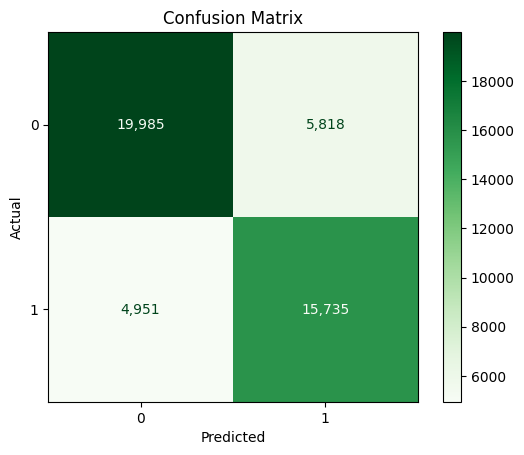

In [21]:
print("Test accuracy:", model.score(X_test, y_test))

y_pred = model.predict(X_test)

f1 = f1_score(y_test, y_pred)
print(f"Binary F1 Score: {f1:.4f}")

# Get predictions from the trained model
y_pred = model.predict(X_test)

# Compute the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
disp.plot(cmap=plt.cm.Greens, values_format=',d')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

**Adding mental health variables added only a marginal improvement to the model's predictive strength.**

Going forward, I will explore different outcome variables: particularly marijuana use within the past month and cocaine use, respectively.

I will also discuss findings with my teammates and combine significant predictor variables into a model.

Lastly, we may design models that predict multiple outcomes: marijuana use or cocaine use or alcohol use rather than binary yes/no.